# 02 · Limpieza del S&P 500 point-in-time

**Dataset de partida:** `sp500_history.parquet`: un único archivo con 7,25 M de filas (valor × día) de 1.289 valores, incluidas las deslistadas, del 02/01/1990 al 30/01/2026. Cada fila lleva el precio del día y un indicador `in_sp500` (1 si el valor era miembro del índice ese día).

**Objetivo:** el mismo que en `01_limpieza_nasdaq100.ipynb`. Construir un panel point-in-time limpio y trazable, sin sesgo de supervivencia ni look-ahead, con **las mismas reglas de limpieza**. Las reglas están en el paquete común `src/limpieza_pit/`, así que ambos índices se tratan exactamente igual.

**Qué cambia respecto al Nasdaq 100.** Las decisiones son las mismas, pero la estructura de los datos es distinta y eso obliga a pasos adicionales:

| | Nasdaq 100 | S&P 500 |
|---|---|---|
| Formato | 15 tablas documentadas (LEEME, SHA256, informes de huecos) | 1 archivo, sin documentación ni checksums |
| Pertenencia | Periodos explícitos | Hay que **reconstruirla** a partir de `in_sp500` (sección 2) |
| Huecos | Filas con `has_price = False` | **La fila no existe**: se detectan comparando con el calendario |
| Precios | 4 variantes de ajuste, float64 | `close` (= retorno total) y `unadjusted_close`, float32 |
| Extra | — | Sector, industria y subsector (clasificación **actual**, no histórica) |

Las justificaciones detalladas de cada decisión están en el notebook 01. Aquí se resumen y se señalan las diferencias.

| Sección | Contenido |
|---|---|
| 0 | Configuración y parámetros |
| 1 | Carga y verificación de integridad |
| 2 | Reconstrucción de la pertenencia point-in-time |
| 3 | Diagnóstico de huecos |
| 4 | Política de limpieza |
| 5 | Validaciones (incluida la validación cruzada con el Nasdaq 100 y la prueba de look-ahead) |
| 6 | Informe antes / después |
| 7 | Exportación |

## 0. Configuración

In [1]:
%load_ext autoreload
%autoreload 2

import platform
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

# Raíz del proyecto (contiene src/) y paquete común de limpieza
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'limpieza_pit').is_dir())
sys.path.insert(0, str(RAIZ / 'src'))

from limpieza_pit.calendario import (Calendario, clasificar_tramos, expandir_periodos, identificar_tramos,
                                     periodos_desde_indicador)
from limpieza_pit.exportacion import (anadir_columnas, construir_log, escribir_parquet, guardar_informe,
                                      resumen_decisiones, sustituir_filas)
from limpieza_pit.graficos import (COLOR, aplicar_estilo, grafico_crecimiento, grafico_mapa_huecos,
                                   grafico_miembros_supervivientes)
from limpieza_pit.integridad import sha256_archivo, verificar_hash
from limpieza_pit.limpieza import (PARAMETROS_POR_DEFECTO, aplicar_limpieza, anadir_ultimo_precio_real,
                                   clasificar_filas_sin_precio, detectar_saltos_split, imputar_ffill_causal,
                                   marcar_precios_congelados, marcar_retornos_anomalos,
                                   marcar_salida_por_fin_cotizacion, marcar_valores_descartados,
                                   recalcular_retornos, valores_imputados)
from limpieza_pit.utilidades import ver_codigo
from limpieza_pit.validacion import (COLUMNAS_CAUSALES, comprobaciones_basicas, control_negativo_lookahead,
                                     detectar_reversiones, limpieza_trampa_interpolacion, ohlc_incoherente,
                                     prueba_lookahead)

ARCHIVO = RAIZ / 'sp500_history.parquet'
DIR_NASDAQ = RAIZ / 'NASDAQ100_PIT_1993-10-01_2026-05-29_CON_HUECOS'   # para calendario y validación cruzada
DIR_SALIDA = RAIZ / 'datos_limpios' / 'sp500'
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
aplicar_estilo()

T_INICIO = time.time()
print('Archivo  :', ARCHIVO)
print('Salida   :', DIR_SALIDA)
print('Python', platform.python_version(), '| pandas', pd.__version__, '| pyarrow', pa.__version__)

Archivo  : /Users/andrealaba/Desktop/TFM/sp500_history.parquet
Salida   : /Users/andrealaba/Desktop/TFM/datos_limpios/sp500
Python 3.11.9 | pandas 3.0.0 | pyarrow 23.0.1


### Parámetros

Son los mismos valores por defecto que en el Nasdaq 100 (`PARAMETROS_POR_DEFECTO`). Solo cambian las fechas de corte de la prueba de look-ahead, elegidas en mitad de huecos reales de este dataset.

In [2]:
PARAMS = {
    **PARAMETROS_POR_DEFECTO,
    # Días sin precio de miembros: 260581 (1998), BIIB (2006) y 528866 (2023)
    'CORTES_TEST_LOOKAHEAD': ['1998-08-28', '2006-03-07', '2023-05-01'],
}
F = PARAMS['FFILL_MAX_SESIONES']
PARAMS

{'FFILL_MAX_SESIONES': 5,
 'UMBRAL_HUECOS_VALOR': None,
 'UMBRAL_RET_ANOMALO': 0.5,
 'UMBRAL_DIF_AJUSTE': 0.2,
 'TOL_SPLIT': 0.02,
 'TOL_OHLC': 1e-06,
 'RACHA_CONGELADO': 5,
 'CORTES_TEST_LOOKAHEAD': ['1998-08-28', '2006-03-07', '2023-05-01']}

## 1. Carga y verificación de integridad

### 1.1 Huella SHA256

El archivo no trae `SHA256SUMS.txt`. Registramos su huella el día en que se incorporó al proyecto (15/10/2026) y comprobamos en cada ejecución que no ha cambiado. Si se sustituye por otra versión, el notebook se detiene y hay que revisar el análisis.

In [3]:
SHA256_REFERENCIA = 'd02e13672f558469d8345ff4dfe0067c460c1729d8b7538d295c3940f35fdecd'
t0 = time.time()
verificar_hash(ARCHIVO, SHA256_REFERENCIA)
print(f'✔ {ARCHIVO.name} sin cambios ({ARCHIVO.stat().st_size / 1e6:,.0f} MB, {time.time() - t0:.1f} s)')

✔ sp500_history.parquet sin cambios (267 MB, 0.2 s)


### 1.2 Esquema

Sin diccionario de esquemas, fijamos aquí el esquema esperado y lo comparamos con los metadatos del archivo (sin cargar datos).

In [4]:
ESQUEMA_ESPERADO = {
    'date': 'timestamp[ns]', 'symbol': 'string', 'assetid': 'int64', 'security_name': 'string',
    'sector': 'string', 'industry': 'string', 'subsector': 'string', 'in_sp500': 'int32',
    'open': 'float', 'high': 'float', 'low': 'float', 'close': 'float', 'volume': 'float',
    'unadjusted_close': 'float',
}
esquema = pq.read_schema(ARCHIVO)
real = {c.name: str(c.type) for c in esquema}
assert real == ESQUEMA_ESPERADO, real
meta = pq.ParquetFile(ARCHIVO).metadata
print(f'✔ esquema esperado | {meta.num_rows:,} filas | {meta.num_row_groups} row groups')

✔ esquema esperado | 7,250,110 filas | 1289 row groups


### 1.3 Carga selectiva y esquema de trabajo

Se cargan solo las columnas necesarias y se renombran al **esquema común** del paquete (el del Nasdaq 100), para que las mismas funciones sirvan para ambos índices:

| Columna original | Esquema común | Comprobación |
|---|---|---|
| `close` | `close_totalreturn` | Coincide con `close_totalreturn` del Nasdaq 100 (validación cruzada, sección 5.6) |
| `unadjusted_close` | `close_none` | Precio sin ajustar |
| `volume` | `volume_none` | |

> **Decisión:** los precios se convierten de float32 a **float64** antes de calcular nada.
>
> **Por qué:** float32 solo guarda unos 7 dígitos significativos. Sería suficiente para los niveles de precio, pero introduce errores de redondeo al encadenar miles de retornos diarios.

La metadata (símbolo, nombre, sector…) es **fija por valor**: es la del snapshot actual. Se guarda aparte, una fila por valor.

In [5]:
COLUMNAS_TRABAJO = {'close': 'close_totalreturn', 'unadjusted_close': 'close_none', 'volume': 'volume_none'}
historia = pd.read_parquet(ARCHIVO, columns=['date', 'assetid', 'in_sp500', *COLUMNAS_TRABAJO]).rename(columns=COLUMNAS_TRABAJO)
for c in COLUMNAS_TRABAJO.values():
    historia[c] = historia[c].astype('float64')
historia = historia.sort_values(['date', 'assetid'], ignore_index=True)

meta_cols = ['symbol', 'security_name', 'sector', 'industry', 'subsector']
metadata = pd.read_parquet(ARCHIVO, columns=['assetid', *meta_cols])
variables = metadata.groupby('assetid')[meta_cols].nunique(dropna=False)
assert (variables <= 1).all().all(), 'La metadata cambia dentro de un valor'
metadata = metadata.drop_duplicates('assetid').set_index('assetid')
# Norgate añade el sufijo -AAAAMM (año y mes de baja) al símbolo de los valores deslistados
metadata['deslistado'] = metadata['symbol'].str.contains(r'-\d{6}$')
SIMBOLO = metadata['symbol']

print(f'historia : {len(historia):,} filas | {historia.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
print(f"valores  : {len(metadata):,} | deslistados hoy: {int(metadata['deslistado'].sum())} | "
      f"metadata fija por valor ✔ | filas sin sector: {int(metadata['sector'].isna().sum())} valores")

historia : 7,250,110 filas | 319 MB
valores  : 1,289 | deslistados hoy: 638 | metadata fija por valor ✔ | filas sin sector: 8 valores


> **Aviso sobre sector, industria y subsector.** Son la clasificación **actual** de cada valor, repetida en todas sus fechas, no la que tenía en cada momento. Las clasificaciones sectoriales han cambiado (por ejemplo, la reforma de GICS de 2018 creó *Communication Services*). Usarlas como si fueran históricas introduce **look-ahead**. Se exportan tal cual, con esta advertencia.

## 2. Reconstrucción de la pertenencia point-in-time

### 2.1 Calendario de sesiones

Para detectar las filas que faltan hace falta un calendario de referencia independiente del propio archivo. Usamos las sesiones del `$NDX` (del dataset del Nasdaq 100, mismo mercado y mismos festivos) y comprobamos que coinciden con las fechas del archivo.

In [6]:
fechas_archivo = pd.DatetimeIndex(historia['date'].unique()).sort_values()
INICIO, FIN = fechas_archivo[0], fechas_archivo[-1]

idx = pd.read_parquet(DIR_NASDAQ / 'indices_referencia.parquet', columns=['symbol', 'date'])
ndx = pd.DatetimeIndex(pd.to_datetime(idx.loc[idx['symbol'] == '$NDX', 'date']))
ndx_rango = ndx[(ndx >= INICIO) & (ndx <= FIN)]
print(f'Sesiones $NDX sin ninguna fila en el archivo: {len(ndx_rango.difference(fechas_archivo))} | '
      f'fechas del archivo que no son sesión $NDX: {len(fechas_archivo.difference(ndx))}')

CAL = Calendario(ndx.union(fechas_archivo))
SESIONES_COBERTURA = CAL.sesiones[(CAL.sesiones >= INICIO) & (CAL.sesiones <= FIN)]
print('Calendario:', CAL, f'| cobertura del archivo: {INICIO.date()} → {FIN.date()} ({len(SESIONES_COBERTURA):,} sesiones)')

Sesiones $NDX sin ninguna fila en el archivo: 0 | fechas del archivo que no son sesión $NDX: 0
Calendario: Calendario(1985-01-31 → 2026-05-29, 10,411 sesiones) | cobertura del archivo: 1990-01-02 → 2026-01-30 (9,087 sesiones)


### 2.2 Periodos de pertenencia a partir de `in_sp500`

El archivo no trae periodos de pertenencia: los reconstruimos con `periodos_desde_indicador`.

> **Decisión:** un **periodo** es una secuencia de filas con `in_sp500 = 1` sin ninguna fila con `in_sp500 = 0` entre medias. Las sesiones **sin fila** dentro de un periodo cuentan como pertenencia: el valor era miembro el día anterior y el siguiente, así que es un hueco de precio, no una salida del índice.
>
> **Por qué:** es la interpretación más prudente. No inventa entradas ni salidas que el dato no muestra, y hace visibles los huecos de precio de los miembros, que de otro modo desaparecerían sin dejar rastro.
>
> **Caso ambiguo:** las sesiones sin fila entre un día con `in_sp500 = 1` y otro con `0` (o al revés) no se asignan a ningún periodo. Su pertenencia es desconocida y no se puede deducir sin mirar al futuro. Se cuentan abajo.

In [7]:
ver_codigo(periodos_desde_indicador)
periodos = periodos_desde_indicador(historia, CAL, INICIO, FIN)

# Sesiones sin fila entre un 1 y un 0 (pertenencia desconocida): quedan fuera del panel
s = historia[['assetid', 'date', 'in_sp500']].sort_values(['assetid', 'date'])
salto = pd.Series(CAL.posicion(s['date']), index=s.index).groupby(s['assetid']).diff() - 1
previo = s.groupby('assetid')['in_sp500'].shift()
ambiguo = (salto > 0) & previo.notna() & (previo != s['in_sp500'])

n_periodos = periodos.groupby('assetid').size()
display(pd.Series({
    'valores que alguna vez fueron miembros': periodos['assetid'].nunique(),
    'periodos de pertenencia': len(periodos),
    'valores con reentradas (más de un periodo)': int((n_periodos > 1).sum()),
    'periodos censurados a la izquierda (miembro el 02/01/1990)': int(periodos['left_censored'].sum()),
    'periodos censurados a la derecha (miembro el 30/01/2026)': int(periodos['right_censored'].sum()),
    'sesiones sin fila DENTRO de un periodo (huecos de precio)': int(periodos['sesiones_sin_fila'].sum()),
    'tramos ambiguos (entre un 1 y un 0), fuera del panel': int(ambiguo.sum()),
    '  sesiones en esos tramos': int(salto[ambiguo].sum()),
}, name='n').to_frame())

`src/limpieza_pit/calendario.py` · **`periodos_desde_indicador`**
```python
def periodos_desde_indicador(filas, cal, inicio, fin, col_miembro='in_sp500'):
    """Reconstruye periodos de pertenencia a partir de un indicador diario 0/1.

    Se usa cuando el dataset no trae los periodos explícitos (p. ej. el S&P 500, donde
    cada fila de precio lleva ``in_sp500``). Un periodo es una secuencia de filas con
    indicador 1 **sin ninguna fila con indicador 0 entre medias**. Las sesiones sin fila
    dentro de un periodo se consideran de pertenencia (son huecos de precio); las que
    caen entre una fila con 1 y otra con 0 no se asignan, porque su pertenencia es
    desconocida.

    ``inicio`` y ``fin`` son el primer y último día de cobertura del dataset: un periodo
    que empieza (termina) en ellos está censurado a la izquierda (derecha).
    """
    f = filas[['assetid', 'date', col_miembro]].sort_values(['assetid', 'date'])
    nuevo_bloque = (f['assetid'] != f['assetid'].shift()) | (f[col_miembro] != f[col_miembro].shift())
    f = f.assign(bloque=nuevo_bloque.cumsum())
    periodos = (f[f[col_miembro] == 1].groupby('bloque')
                .agg(assetid=('assetid', 'first'), first_included_session=('date', 'min'),
                     last_included_session=('date', 'max'), filas_observadas=('date', 'size'))
                .reset_index(drop=True))
    periodos.insert(1, 'membership_period', periodos.groupby('assetid').cumcount().add(1).astype('int32'))
    periodos['sesiones'] = (cal.posicion(periodos['last_included_session'])
                            - cal.posicion(periodos['first_included_session']) + 1).astype(int)
    periodos['sesiones_sin_fila'] = periodos['sesiones'] - periodos['filas_observadas']
    periodos['left_censored'] = periodos['first_included_session'] == pd.Timestamp(inicio)
    periodos['right_censored'] = periodos['last_included_session'] == pd.Timestamp(fin)
    return periodos
```

,n
valores que alguna vez fueron miembros,1289
periodos de pertenencia,1321
valores con reentradas (más de un periodo),32
periodos censurados a la izquierda (miembro el 02/01/1990),500
periodos censurados a la derecha (miembro el 30/01/2026),503
sesiones sin fila DENTRO de un periodo (huecos de precio),34
"tramos ambiguos (entre un 1 y un 0), fuera del panel",5
sesiones en esos tramos,31


### 2.3 Panel diario de pertenencia

Expandimos cada periodo a sus sesiones y unimos los precios con una unión izquierda. Las sesiones de pertenencia sin fila en el archivo quedan con `has_price = False`, igual que en el panel del Nasdaq 100.

In [8]:
panel = (expandir_periodos(periodos, SESIONES_COBERTURA)
         .merge(historia[['date', 'assetid', 'close_totalreturn', 'close_none', 'volume_none']],
                on=['date', 'assetid'], how='left', validate='one_to_one'))
panel['has_price'] = panel['close_totalreturn'].notna()
panel = panel.sort_values(['date', 'assetid'], ignore_index=True)
assert not panel.duplicated(['date', 'assetid']).any()
# Toda fila con in_sp500 = 1 del archivo debe estar en el panel
assert panel['has_price'].sum() == (historia['in_sp500'] == 1).sum()

panel_base = panel.copy()          # copia sin modificar para la prueba de look-ahead (5.8)
historia_precios = historia[['assetid', 'date', 'close_totalreturn', 'close_none']]

miembros_dia = panel.groupby('date').size()
print(f"Panel: {len(panel):,} filas (valor × sesión de pertenencia) | sin precio: {int((~panel['has_price']).sum())}")
print(f'Miembros por sesión: mín {miembros_dia.min()} | mediana {miembros_dia.median():.0f} | máx {miembros_dia.max()} '
      f'| sesiones con menos de 500: {int((miembros_dia < 500).sum())}')
display(miembros_dia[miembros_dia < 500].groupby(miembros_dia[miembros_dia < 500].index.year)
        .agg(['size', 'min']).rename(columns={'size': 'sesiones_menos_500', 'min': 'min_miembros'}).T)

Panel: 4,555,058 filas (valor × sesión de pertenencia) | sin precio: 34
Miembros por sesión: mín 498 | mediana 500 | máx 507 | sesiones con menos de 500: 87


date,1992,1993,1994,1995,1997,1998,1999,2000,2001,2002,2003,2005,2006,2007,2008,2009,2010,2011,2012,2013
sesiones_menos_500,1,3,1,1,5,3,2,9,8,2,5,3,1,4,14,8,4,2,8,3
min_miembros,499,499,499,499,499,499,499,498,499,499,499,499,499,499,498,499,499,499,499,499


**Sesiones con menos de 500 miembros.** El S&P 500 tiene 500 empresas, pero algunas cotizan con dos clases de acciones (GOOGL/GOOG, FOXA/FOX…), por eso lo normal son 500–505 valores. Las sesiones con 498–499 miembros suelen corresponder a días de recomposición, en los que la salida y la entrada no se registran la misma sesión, o a lagunas de la fuente. No se pueden corregir con este archivo y se documentan aquí.

### 2.4 Por qué importa conservar las deslistadas

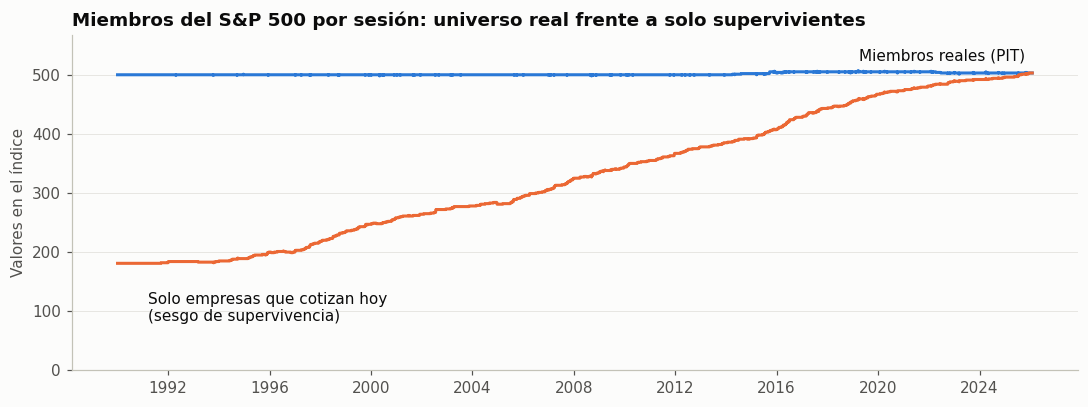

date,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% filas de miembro de empresas hoy deslistadas,63.8000,63.7000,63.2000,63.3000,62.6000,61.2000,60.0000,58.2000,54.9000,51.8000,49.9000,47.8000,46.3000,44.7000,43.8000,...,25.6000,23.9000,22.3000,20.4000,16.7000,13.4000,11.4000,8.8000,6.7000,5.5000,3.8000,2.5000,1.9000,0.9000,0.0000


In [9]:
deslistado = panel['assetid'].map(metadata['deslistado'])
miembros = pd.DataFrame({'todos': miembros_dia,
                         'solo_supervivientes': (~deslistado).groupby(panel['date']).sum()})
grafico_miembros_supervivientes(miembros, 'S&P 500')
pct_deslistadas = 100 * deslistado.groupby(panel['date'].dt.year).mean()
display(pd.DataFrame({'% filas de miembro de empresas hoy deslistadas': pct_deslistadas}).T.round(1))

> **Decisión:** igual que en el Nasdaq 100, el universo de cada día es el reconstruido a partir de `in_sp500`, con todos los valores, coticen hoy o no. Nunca se filtra por el símbolo ni por ningún dato del snapshot actual.

## 3. Diagnóstico de huecos

### 3.1 Tramos sin precio dentro de la pertenencia

Mismo método que en el Nasdaq 100: tramos de sesiones consecutivas sin precio y su clase (A · sin cotización puntual, B · prolongado, C · sin historia previa).

*El diagnóstico mira el precio posterior al tramo, pero solo para describir: las reglas de la sección 4 no lo usan.*

In [10]:
CLAVES = ['date', 'assetid', 'membership_period']
sin_precio, tramos = identificar_tramos(panel.loc[~panel['has_price'], CLAVES], CAL)
tramos = clasificar_tramos(tramos, historia[['assetid', 'date']], CAL, F)
tramos['simbolo'] = tramos['assetid'].map(SIMBOLO)
print(f"{len(sin_precio)} filas sin precio en {len(tramos)} tramos y {tramos['assetid'].nunique()} valores")
display(tramos['clase'].value_counts().to_frame('tramos'))
display(tramos.sort_values('inicio')[['simbolo', 'assetid', 'inicio', 'fin', 'sesiones', 'precio_anterior',
                                      'precio_posterior', 'hueco_serie_sesiones', 'clase']].reset_index(drop=True))

34 filas sin precio en 31 tramos y 23 valores


,tramos
clase,
A · sin cotización puntual,31


,simbolo,assetid,inicio,fin,sesiones,precio_anterior,precio_posterior,hueco_serie_sesiones,clase
0,GWOW-201009,389389,1990-02-21,1990-02-21,1,1990-02-20,1990-02-22,1.0000,A · sin cotización puntual
1,BNSSA-201206,130361,1990-10-08,1990-10-08,1,1990-10-05,1990-10-09,1.0000,A · sin cotización puntual
2,GWOW-201009,389389,1990-11-05,1990-11-05,1,1990-11-02,1990-11-06,1.0000,A · sin cotización puntual
3,BSET,126103,1990-12-26,1990-12-26,1,1990-12-24,1990-12-27,1.0000,A · sin cotización puntual
4,WLBAQ-202004,131728,1990-12-26,1990-12-26,1,1990-12-24,1990-12-27,1.0000,A · sin cotización puntual
5,GWOW-201009,389389,1991-01-10,1991-01-10,1,1991-01-09,1991-01-11,1.0000,A · sin cotización puntual
6,AMT-199607,258665,1991-01-11,1991-01-11,1,1991-01-10,1991-01-14,1.0000,A · sin cotización puntual
7,BNSSA-201206,130361,1991-05-03,1991-05-03,1,1991-05-02,1991-05-06,1.0000,A · sin cotización puntual
8,BNSSA-201206,130361,1991-05-28,1991-05-28,1,1991-05-24,1991-05-29,1.0000,A · sin cotización puntual
9,BNSSA-201206,130361,1991-09-17,1991-09-17,1,1991-09-16,1991-09-18,1.0000,A · sin cotización puntual


**Lectura.**
- Todos los huecos de miembros son de **1 o 2 sesiones** y tienen precio el día anterior y el siguiente (clase A).
- No hay tramos prolongados: el S&P 500 **no sufre las particiones dañadas** del Nasdaq 100.
- Varios coinciden con los huecos aislados del Nasdaq 100: BIIB (07/03/2006, 06/11/2020, 09/06/2023), VRTX (12/05/2015), REGN (09/06/2015) y MEDI (17/12/2002). Que dos extracciones distintas coincidan confirma que son **días sin cotización en la fuente**, no errores de uno de los datasets.

### 3.2 Huecos fuera de la pertenencia

Como en el Nasdaq 100, también hay sesiones sin precio en días en que el valor **no** era miembro. No afectan al panel point-in-time y no se tocan.

In [11]:
span = historia.groupby('assetid')['date'].agg(primera='min', ultima='max', n_precios='size')
span['sesiones_sin_precio_serie'] = (CAL.posicion(span['ultima']) - CAL.posicion(span['primera']) + 1
                                     - span['n_precios'])
display(pd.Series({
    'Sesiones sin precio dentro de la serie de cada valor': int(span['sesiones_sin_precio_serie'].sum()),
    '  de ellas, en días de pertenencia (panel)': len(sin_precio),
    '  en tramos de pertenencia ambigua (sección 2.2)': int(salto[ambiguo].sum()),
    '  fuera de la pertenencia (no afectan al panel)': int(span['sesiones_sin_precio_serie'].sum()
                                                           - len(sin_precio) - salto[ambiguo].sum()),
    'valores con alguna sesión sin precio en su serie': int((span['sesiones_sin_precio_serie'] > 0).sum()),
}, name='n').to_frame())

,n
Sesiones sin precio dentro de la serie de cada valor,16868
"de ellas, en días de pertenencia (panel)",34
en tramos de pertenencia ambigua (sección 2.2),31
fuera de la pertenencia (no afectan al panel),16803
valores con alguna sesión sin precio en su serie,242


## 4. Política de limpieza

Se aplican **las mismas funciones y los mismos parámetros** que en el Nasdaq 100. Resumen de las decisiones (justificación completa en el notebook 01, sección 4):

| # | Decisión | Efecto esperado en el S&P 500 |
|---|---|---|
| 4.0 | Retornos con `close_totalreturn`; `close_none` solo para validar splits | — |
| 4.2 | Forward-fill **causal** de como máximo 5 sesiones, marcado en `precio_imputado` | Rellena los 34 huecos (todos ≤ 2 sesiones) |
| 4.3 | Lo que no se rellena se marca `excluible`, sin borrar la fila | Ninguna fila |
| 4.4 | **Opción B**: no se descarta ningún valor completo | — |
| 4.5 | Retorno NaN tras un hueco de más de 5 sesiones; acumulado tras uno corto | Solo retornos acumulados |

### 4.1 Último precio real conocido (solo pasado)

In [12]:
panel = anadir_ultimo_precio_real(panel, historia_precios, CAL)
print(f"Filas sin ningún precio anterior (primer día de cada serie): {int(panel['fecha_ultimo_precio_real'].isna().sum())}")

Filas sin ningún precio anterior (primer día de cada serie): 512


### 4.2 Forward-fill causal

In [13]:
ver_codigo(imputar_ffill_causal)
panel = imputar_ffill_causal(panel, F)

# Valores para el panel completo (sección 7): OHLC = último cierre, unadjusted_close = último sin ajustar
ids_imputados = panel.loc[panel['precio_imputado'], 'assetid'].unique().tolist()
precios_imp = (pd.read_parquet(ARCHIVO, columns=['assetid', 'date', 'close', 'unadjusted_close'],
                               filters=[('assetid', 'in', ids_imputados)]))
imputados = valores_imputados(panel, precios_imp, ['close', 'unadjusted_close'],
                              {c: 'close' for c in ['open', 'high', 'low']})
print(f"Filas imputadas: {int(panel['precio_imputado'].sum())} en {len(ids_imputados)} valores")

`src/limpieza_pit/limpieza.py` · **`imputar_ffill_causal`**
```python
def imputar_ffill_causal(panel, max_sesiones):
    """Rellena con el último precio real las filas sin precio si han pasado <= ``max_sesiones`` sesiones.

    El criterio es «sesiones desde el último precio», no «duración total del hueco»
    (que solo se conoce al terminar el hueco y sería look-ahead). Marca ``precio_imputado``;
    ``has_price`` conserva su valor original.
    """
    imputar = ~panel['has_price'] & panel['sesiones_desde_ultimo_precio'].le(max_sesiones)
    panel['precio_imputado'] = imputar
    panel['close_totalreturn'] = panel['close_totalreturn'].mask(imputar, panel['close_tr_previo'])
    panel['close_none'] = panel['close_none'].mask(imputar, panel['close_none_previo'])
    return panel
```

Filas imputadas: 34 en 23 valores


### 4.3 – 4.5 Clasificación, opción B y retornos

In [14]:
panel = clasificar_filas_sin_precio(panel)
panel, pct_excluible = marcar_valores_descartados(panel, PARAMS['UMBRAL_HUECOS_VALOR'])
panel = recalcular_retornos(panel, F)

display(panel.groupby('tipo_hueco').agg(filas=('date', 'size'), valores=('assetid', 'nunique')))
display(panel.groupby('motivo_ret').agg(filas=('date', 'size'), valores=('assetid', 'nunique'),
                                        ret_medio=('ret_tr_limpio', 'mean')))

,filas,valores
tipo_hueco,,
imputado_ffill,34,23
ninguno,4555024,1289


,filas,valores,ret_medio
motivo_ret,,,
acumulado_tras_hueco_corto,32,24,-0.0366
imputado_cero,34,23,0.0000
normal,4554480,1289,0.0005
primer_precio,512,512,NaN


**Lectura.** Todos los huecos se rellenan y ninguna fila queda `excluible`. Los retornos `primer_precio` (NaN) son el primer día de cada serie: los ~500 valores ya presentes el 02/01/1990, más los que entran en el índice el mismo día en que empiezan a cotizar (salidas a bolsa y escisiones).

## 5. Validaciones posteriores

### 5.1 Duplicados y precios no positivos

In [15]:
checks = comprobaciones_basicas(panel)
display(checks.to_frame())
assert checks.eq(0).all()

,resultado
"duplicados (date, assetid)",0
close_totalreturn <= 0 (filas utilizables),0
close_none <= 0 (filas utilizables),0
precio nulo en filas utilizables,0


### 5.2 Coherencia OHLC

Solo hay una variante con OHLC (la ajustada). Se comprueba sobre los valores originales en float32.

In [16]:
ohlc = pd.read_parquet(ARCHIVO, columns=['date', 'assetid', 'open', 'high', 'low', 'close'])
ohlc = panel[['date', 'assetid']].merge(ohlc, on=['date', 'assetid'], how='left')
panel['ohlc_incoherente'], resumen_ohlc = ohlc_incoherente(ohlc, panel['has_price'], [('open', 'high', 'low', 'close')],
                                                           PARAMS['TOL_OHLC'])
display(resumen_ohlc)
del ohlc

,filas_incoherentes,open_nulo_con_precio
close,0,0


### 5.3 Retornos anómalos y saltos por splits

Mismas reglas que en el Nasdaq 100. Este archivo no trae `capital_event`, así que no se puede contrastar con el indicador de eventos de capital.

In [17]:
panel = marcar_retornos_anomalos(panel, PARAMS['UMBRAL_RET_ANOMALO'])
panel = detectar_saltos_split(panel, PARAMS['UMBRAL_DIF_AJUSTE'], PARAMS['TOL_SPLIT'])
anom = panel[panel['ret_anomalo']].assign(simbolo=lambda d: d['assetid'].map(SIMBOLO))
print(f"Operaciones corporativas ajustadas detectadas: {int(panel['accion_corporativa_ajustada'].sum())} | "
      f"retornos anómalos (|r| > {PARAMS['UMBRAL_RET_ANOMALO']:.0%}): {len(anom)} en {anom['assetid'].nunique()} valores | "
      f"posibles splits no ajustados: {int(panel['posible_split_no_ajustado'].sum())}")
cols_ver = ['date', 'simbolo', 'assetid', 'ret_tr_limpio', 'ret_none_limpio', 'motivo_ret', 'posible_split_no_ajustado']
display(anom.sort_values('ret_tr_limpio', key=np.abs, ascending=False)[cols_ver].head(25))
display(panel.loc[panel['posible_split_no_ajustado'], cols_ver[:1] + cols_ver[2:]]
        .assign(simbolo=lambda d: d['assetid'].map(SIMBOLO), nombre=lambda d: d['assetid'].map(metadata['security_name'])))

Operaciones corporativas ajustadas detectadas: 1103 | retornos anómalos (|r| > 50%): 114 en 73 valores | posibles splits no ajustados: 4


,date,simbolo,assetid,ret_tr_limpio,ret_none_limpio,motivo_ret,posible_split_no_ajustado
2386485,2008-12-05,HIG,127369,1.0236,1.0236,normal,True
99333,1990-10-12,ISS-199206,256136,1.0000,1.0000,normal,True
2357817,2008-09-15,LEHMQ-201203,143148,-0.9425,-0.9425,normal,False
134937,1991-01-24,DGN-199910,261712,0.9412,0.9412,normal,False
2362329,2008-09-26,WAMUQ-201203,143629,-0.9053,-0.9053,normal,False
4208945,2023-05-03,FRCB,528866,-0.9050,-0.9050,acumulado_tras_hueco_corto,False
2363072,2008-09-30,WB-200812,131239,0.9022,0.9022,normal,False
2355178,2008-09-08,FNMA,136395,-0.8963,-0.8963,normal,False
685844,1995-06-05,LOTS-199507,257659,0.8923,0.8923,normal,False
1313569,2000-05-24,UAWGQ-200303,130298,0.8892,0.8892,normal,False


,date,assetid,ret_tr_limpio,ret_none_limpio,motivo_ret,posible_split_no_ajustado,simbolo,nombre
99333,1990-10-12,256136,1.0000,1.0000,normal,True,ISS-199206,Interco Inc Common
162049,1991-04-15,128932,-0.6667,-0.6667,normal,True,UH-200005,U.S. Home Corp Common
2386485,2008-12-05,127369,1.0236,1.0236,normal,True,HIG,Hartford Insurance Group Inc Common
2462851,2009-07-16,145007,-0.7500,-0.7500,normal,True,CITGQ-200912,CIT Group Inc Common


**Lectura.** Los retornos anómalos son en su mayoría movimientos reales, sobre todo de la crisis de 2008 (Lehman, Washington Mutual, Fannie Mae…), y se conservan marcados. Los «posibles splits no ajustados» son precios de céntimos a principios de los 90 (Interco, U.S. Home) y saltos de la crisis financiera (Hartford, CIT). Probablemente son movimientos reales, pero quedan marcados para revisión.

### 5.4 Precios congelados y picos que se revierten

In [18]:
panel = marcar_precios_congelados(panel, PARAMS['RACHA_CONGELADO'])
cong = panel[panel['precio_congelado']]
print(f"Filas con precio congelado (>= {PARAMS['RACHA_CONGELADO']} sesiones): {len(cong):,} en {cong['assetid'].nunique()} valores")
display(cong.groupby(cong['date'].dt.year).size().rename('filas').to_frame().T)
display(cong.assign(simbolo=cong['assetid'].map(SIMBOLO)).groupby(['simbolo', 'assetid'])
        .agg(filas=('date', 'size'), desde=('date', 'min'), hasta=('date', 'max'),
             racha_max=('sesiones_mismo_cierre', 'max'), volumen_mediano=('volume_none', 'median'))
        .sort_values('filas', ascending=False).head(15))

reversion, r_manana = detectar_reversiones(panel)
print(f'Picos que se revierten al día siguiente: {int(reversion.sum())}')
display(panel.loc[reversion, ['date', 'assetid', 'close_none', 'ret_tr_limpio']]
        .assign(simbolo=lambda d: d['assetid'].map(SIMBOLO), ret_dia_siguiente=r_manana[reversion]))

Filas con precio congelado (>= 5 sesiones): 1,419 en 282 valores


date,1990,1991,1992,1993,1994,1995,1996,1997,1998,2000,2013,2014
filas,250,219,173,183,159,221,131,70,5,4,2,2


,,filas,desde,hasta,racha_max,volumen_mediano
simbolo,assetid,,,,,
UH-200005,128932,66,1990-02-20,1991-04-12,17,"6,208.3623"
VAT-199609,258770,52,1990-02-23,1991-07-12,18,"28,300.0000"
NAE-199708,259447,36,1992-12-21,1997-08-04,8,"197,911.5000"
CHRS-201206,138314,34,1995-04-17,1997-06-25,13,"216,882.5000"
AS-199909,261680,33,1990-09-18,1997-02-20,8,"107,500.0000"
AAV-199901,260956,31,1992-04-20,1994-08-31,16,"15,827.5840"
NAV-202106,141250,30,1990-06-25,1997-02-26,7,"32,025.0117"
CIC-199505,257547,29,1994-12-19,1995-04-28,12,"60,200.0000"
PPW-199911,261848,25,1991-06-12,1997-04-25,8,"527,599.0625"


Picos que se revierten al día siguiente: 12


,date,assetid,close_none,ret_tr_limpio,simbolo,ret_dia_siguiente
93549,1990-09-27,128932,0.2500,-0.3333,UH-200005,0.5000
94049,1990-09-28,128932,0.3750,0.5000,UH-200005,-0.3333
99333,1990-10-12,256136,0.5000,1.0000,ISS-199206,-0.5000
2336143,2008-07-15,134207,5.2600,-0.2602,FMCC,0.2985
2336179,2008-07-15,136395,7.0700,-0.2734,FNMA,0.3083
2355678,2008-09-09,136395,0.9900,0.3562,FNMA,-0.2525
2366570,2008-10-09,131239,3.6000,-0.2885,WB-200812,0.4306
2369360,2008-10-16,145007,2.9100,-0.3782,CITGQ-200912,0.6151
2378669,2008-11-12,136462,4.4700,-0.3493,PLD-201106,0.5302
2443580,2009-05-21,132085,1.9200,0.3241,MTLQQ-201103,-0.2552


### 5.5 Valores que dejan el índice porque dejan de cotizar

Este archivo no trae `endpoint_at_last_price`, así que lo reconstruimos: son los periodos no censurados a la derecha cuya última sesión coincide con el **último precio** del valor.

In [19]:
ultimo_precio = historia.groupby('assetid')['date'].max()
fin_cot = periodos[~periodos['right_censored']
                   & (periodos['last_included_session'] == periodos['assetid'].map(ultimo_precio))]
panel = marcar_salida_por_fin_cotizacion(panel, fin_cot[['assetid', 'membership_period', 'last_included_session']])

ult20 = (panel.merge(fin_cot[['assetid', 'membership_period']], on=['assetid', 'membership_period'])
         .sort_values('date').groupby(['assetid', 'membership_period']).tail(20)
         .groupby(['assetid', 'membership_period'])['ret_tr_limpio'].apply(lambda r: (1 + r.fillna(0)).prod() - 1))
salidas = panel.loc[panel['salida_por_fin_cotizacion'], ['assetid', 'membership_period', 'date', 'close_none', 'ret_tr_limpio']]
salidas = salidas.join(ult20.rename('ret_ultimas_20'), on=['assetid', 'membership_period'])
salidas.insert(0, 'simbolo', salidas['assetid'].map(SIMBOLO))
salidas.insert(1, 'nombre', salidas['assetid'].map(metadata['security_name']))
print(f"Periodos que terminan con el fin de la serie de precios: {len(salidas)} | "
      f"último cierre < 1 $: {int((salidas['close_none'] < 1).sum())} | "
      f"caída > 50 % en las últimas 20 sesiones: {int((salidas['ret_ultimas_20'] < -0.5).sum())}")
display(salidas.sort_values('ret_ultimas_20').head(15).reset_index(drop=True))

Periodos que terminan con el fin de la serie de precios: 384 | último cierre < 1 $: 0 | caída > 50 % en las últimas 20 sesiones: 0


,simbolo,nombre,assetid,membership_period,date,close_none,ret_tr_limpio,ret_ultimas_20
0,RTN-202004,Raytheon Co Common,146405,1,2020-04-02,116.9600,-0.0447,-0.3661
1,SEG-200011,Seagate Technology Common,265770,1,2000-11-21,49.5000,-0.1239,-0.2800
2,WAI-199808,Western Atlas Inc Common,260392,1,1998-08-10,60.0625,-0.0652,-0.2415
3,IMNX-200207,Immunex Corp Common,267293,1,2002-07-15,16.9900,-0.1309,-0.2178
4,WEN-200809,Wendy's International Common,593138,1,2008-09-29,19.2100,-0.1515,-0.2085
5,CFC-200806,Countrywide Financial Corp Common,138366,1,2008-06-30,4.2500,-0.0385,-0.2011
6,JWP-199310,JWP Inc Common,256741,1,1993-10-08,1.1250,0.0000,-0.1818
7,SOV-200901,Sovereign Bancorp Inc Common,126900,1,2009-01-29,2.4700,-0.0679,-0.1767
8,DRE-202209,Duke Realty Common,129819,1,2022-09-30,48.2000,0.0048,-0.1761
9,BSC-200805,Bear Stearns Companies Common,133972,1,2008-05-30,9.3300,-0.0230,-0.1655


> **Decisión (igual que en el Nasdaq 100):** no se añade un retorno de salida sintético. La última sesión se marca con `salida_por_fin_cotizacion`.
>
> **Por qué apenas importa aquí:** ninguno de estos periodos termina con un precio inferior a 1 $ ni con una caída superior al 50 % en sus últimas 20 sesiones. Son sobre todo fusiones y adquisiciones. Las grandes quiebras (Lehman, Washington Mutual) **salieron del índice antes de dejar de cotizar**, así que su caída sí está en el panel: aparecen entre los retornos anómalos de la sección 5.3.

### 5.6 Validación cruzada con el Nasdaq 100

267 valores están en los dos datasets. Si ambos proceden de la misma fuente, sus precios y retornos deben coincidir en las fechas comunes. Es la mejor validación disponible, porque el archivo no incluye ningún índice de referencia del S&P 500.

In [20]:
univ_ndx = pd.read_parquet(DIR_NASDAQ / 'universo.parquet', columns=['assetid'])['assetid']
comunes = sorted(set(historia['assetid']) & set(univ_ndx))
ndx_p = pd.read_parquet(DIR_NASDAQ / 'precios_diarios.parquet',
                        columns=['assetid', 'date', 'close_totalreturn', 'close_none'], filters=[('assetid', 'in', comunes)])
ndx_p['date'] = pd.to_datetime(ndx_p['date']).astype('datetime64[ns]')
cruce = (historia.loc[historia['assetid'].isin(comunes), ['assetid', 'date', 'close_totalreturn', 'close_none']]
         .merge(ndx_p, on=['assetid', 'date'], suffixes=('_sp', '_ndx')).sort_values(['assetid', 'date']))

g = cruce.groupby('assetid')
consecutiva = pd.Series(CAL.posicion(cruce['date']), index=cruce.index).groupby(cruce['assetid']).diff() == 1
for s in ['sp', 'ndx']:
    cruce[f'ret_{s}'] = g[f'close_totalreturn_{s}'].pct_change(fill_method=None).where(consecutiva)
dif_ret = (cruce['ret_sp'] - cruce['ret_ndx']).abs().dropna()     # solo retornos comparables
dif_none = (cruce['close_none_sp'] / cruce['close_none_ndx'] - 1).abs()
display(pd.Series({
    'valores comunes': len(comunes),
    'filas (valor, fecha) comunes': len(cruce),
    'retornos comparables (sesiones consecutivas en ambos)': len(dif_ret),
    'correlación de retornos diarios': cruce['ret_sp'].corr(cruce['ret_ndx']),
    '% retornos con |diferencia| < 0,01 pp': 100 * (dif_ret < 1e-4).mean(),
    'retornos con |diferencia| > 0,1 pp': int((dif_ret > 1e-3).sum()),
    '% precios sin ajustar iguales (dif. relativa < 1e-6)': 100 * (dif_none < 1e-6).mean(),
}, name='resultado').to_frame())
display(cruce.loc[dif_ret.index[dif_ret > 1e-3], ['date', 'assetid', 'ret_sp', 'ret_ndx']]
        .assign(simbolo=lambda d: d['assetid'].map(SIMBOLO)))

,resultado
valores comunes,267.0000
"filas (valor, fecha) comunes","1,519,027.0000"
retornos comparables (sesiones consecutivas en ambos),"1,517,422.0000"
correlación de retornos diarios,1.0000
"% retornos con |diferencia| < 0,01 pp",99.9998
"retornos con |diferencia| > 0,1 pp",3.0000
% precios sin ajustar iguales (dif. relativa < 1e-6),100.0000


,date,assetid,ret_sp,ret_ndx,simbolo
1490053,2025-05-05,131054,-0.0054,0.0006,JWN-202505
1491469,2025-05-16,131054,0.0076,0.0016,JWN-202505
274394,1997-07-29,141248,0.0207,0.0100,ADBE


**Lectura.** De más de 1,5 millones de retornos comparables, prácticamente todos coinciden a 0,01 pp y los precios sin ajustar son idénticos. Esto confirma que `close` es la variante de retorno total y que ambos archivos proceden de la misma fuente (Norgate). Solo un puñado de retornos difiere en más de 0,1 pp (tabla de arriba), lo que apunta a correcciones puntuales de la fuente entre una extracción y otra. Las diferencias mínimas restantes son redondeo de float32.

#### Hallazgo: el S&P 500 tiene precio para la mayoría de los huecos del Nasdaq 100

Si los dos archivos proceden de la misma fuente, el S&P 500 podría rellenar huecos del Nasdaq 100 con **precios reales** en lugar de dejarlos como `excluible`.

In [21]:
huecos_ndx = pd.read_parquet(DIR_NASDAQ / 'miembros_sin_precio.parquet', columns=['date', 'assetid'])
huecos_ndx['date'] = pd.to_datetime(huecos_ndx['date']).astype('datetime64[ns]')
recuperables = huecos_ndx.merge(historia[['assetid', 'date', 'close_totalreturn']], on=['assetid', 'date'], how='left')
por_valor_rec = (recuperables.groupby('assetid')
                 .agg(huecos_nasdaq=('date', 'size'), con_precio_en_sp500=('close_totalreturn', lambda s: int(s.notna().sum()))))
por_valor_rec.insert(0, 'simbolo', por_valor_rec.index.map(SIMBOLO))
print(f"Huecos del Nasdaq 100: {len(huecos_ndx):,} | con precio en el archivo del S&P 500: "
      f"{int(recuperables['close_totalreturn'].notna().sum()):,} "
      f"({100 * recuperables['close_totalreturn'].notna().mean():.0f} %)")
display(por_valor_rec[por_valor_rec['con_precio_en_sp500'] > 0].sort_values('huecos_nasdaq', ascending=False))

Huecos del Nasdaq 100: 24,975 | con precio en el archivo del S&P 500: 21,996 (88 %)


,simbolo,huecos_nasdaq,con_precio_en_sp500
assetid,,,
144108,BBBYQ-202309,4536,4536
136428,AABA-201910,4100,4100
145519,LRCX,3073,3073
125619,NOVL-201104,2010,2010
131183,QLGC-201608,1508,1508
127575,EXC,1285,1285
129132,CIEN,1102,1102
168627,WBD,1014,1014
273651,TMUS,1008,1008


> **Decisión:** este hallazgo **no se aplica todavía** a la limpieza del Nasdaq 100. Queda pendiente de confirmar con el profesor el origen y la fecha de extracción de `sp500_history.parquet`, que no trae documentación.
>
> **Por qué:** mezclar dos fuentes requiere saber que son comparables. Si se aplica, se haría empalmando **retornos** (no niveles, porque los ajustes pueden diferir) y marcando cada fila recuperada con una columna como `precio_fuente_sp500`.

### 5.7 Prueba de ausencia de look-ahead

Misma prueba que en el Nasdaq 100: la limpieza con los datos truncados en `T` debe dar exactamente las mismas filas `≤ T` que con el dataset completo. Los cortes caen en días sin precio de miembros.

Como **control negativo** no sirve el *backfill* que se usó en el Nasdaq: aquí todos los huecos se rellenan y no queda ningún NaN que un *backfill* pueda delatar. Se usa en su lugar una **interpolación lineal** entre el precio anterior y el siguiente, un error frecuente que también mira al futuro.

In [22]:
ver_codigo(limpieza_trampa_interpolacion)
completo = aplicar_limpieza(panel_base, historia_precios, CAL, PARAMS)
pd.testing.assert_frame_equal(completo[COLUMNAS_CAUSALES], panel[COLUMNAS_CAUSALES])
print('✔ aplicar_limpieza reproduce exactamente el panel de la sección 4')

display(prueba_lookahead(panel_base, historia_precios, CAL, PARAMS, PARAMS['CORTES_TEST_LOOKAHEAD'], referencia=completo))
del completo

corte = PARAMS['CORTES_TEST_LOOKAHEAD'][-1]
n_distintas = control_negativo_lookahead(panel_base, historia_precios, CAL, PARAMS, corte,
                                         limpieza=limpieza_trampa_interpolacion)
print(f'Limpieza trampa (interpolación): {n_distintas:,} filas hasta {corte} cambian al conocer el futuro')
print('✔ la prueba de truncamiento detecta el look-ahead cuando existe')

`src/limpieza_pit/validacion.py` · **`limpieza_trampa_interpolacion`**
```python
def limpieza_trampa_interpolacion(panel_base, historia, cal, params, evaluacion=None):
    """Limpieza con look-ahead deliberado: interpola linealmente los precios imputados entre
    el precio anterior y el SIGUIENTE (error habitual). Sirve aunque no queden huecos sin rellenar."""
    p = aplicar_limpieza(panel_base, historia, cal, params, evaluacion)
    sin_imputar = p['close_totalreturn'].mask(p['precio_imputado'])
    p['close_totalreturn'] = sin_imputar.groupby(p['assetid']).transform(lambda s: s.interpolate(limit_area='inside'))
    return p
```

✔ aplicar_limpieza reproduce exactamente el panel de la sección 4


,corte,filas_comparadas,imputadas_hasta_T,imputadas_el_dia_T,excluibles_el_dia_T,resultado
0,1998-08-28,1094989,18,1,0,idénticas ✔
1,2006-03-07,2039956,25,1,0,idénticas ✔
2,2023-05-01,4208000,32,1,0,idénticas ✔


Limpieza trampa (interpolación): 1 filas hasta 2023-05-01 cambian al conocer el futuro
✔ la prueba de truncamiento detecta el look-ahead cuando existe


## 6. Informe antes / después

### 6.1 Cobertura por año

In [23]:
anio = panel['date'].dt.year
g = panel.groupby(anio)
cobertura_anual = pd.DataFrame({
    'filas_miembro': g.size(),
    'valores_miembro': g['assetid'].nunique(),
    'pct_precio_real_antes': 100 * g['has_price'].mean(),
    'pct_precio_utilizable_despues': 100 * g['precio_utilizable'].mean(),
    'filas_imputadas': g['precio_imputado'].sum(),
    'ret_acumulado_tras_hueco': (panel['motivo_ret'] == 'acumulado_tras_hueco_corto').groupby(anio).sum(),
    'ret_anomalos': g['ret_anomalo'].sum(),
    'precios_congelados': g['precio_congelado'].sum(),
})
cobertura_anual.index.name = 'anio'
display(cobertura_anual.round(3))

,filas_miembro,valores_miembro,pct_precio_real_antes,pct_precio_utilizable_despues,filas_imputadas,ret_acumulado_tras_hueco,ret_anomalos,precios_congelados
anio,,,,,,,,
1990,126500,513,99.9960,100.0000,5,5,6,250
1991,126500,509,99.9960,100.0000,5,5,6,219
1992,126999,507,99.9990,100.0000,1,1,2,173
1993,126497,511,100.0000,100.0000,0,0,1,183
1994,126000,517,99.9980,100.0000,2,2,1,159
1995,125999,526,100.0000,100.0000,0,0,2,221
1996,127000,519,100.0000,100.0000,0,0,0,131
1997,126495,525,99.9990,100.0000,1,1,0,70
1998,125997,538,99.9960,100.0000,5,4,0,5


### 6.2 Resumen por decisión

In [24]:
DECISIONES = {
    '4.2 precio imputado (ffill causal)': panel['precio_imputado'],
    '4.3 excluible: prolongado sin imputar': panel['tipo_hueco'] == 'prolongado_sin_imputar',
    '4.3 excluible: sin precio previo': panel['tipo_hueco'] == 'sin_precio_previo',
    '4.4 valor descartado (opción A)': panel['valor_descartado'],
    '4.5 retorno acumulado tras hueco corto': panel['motivo_ret'] == 'acumulado_tras_hueco_corto',
    '4.5 retorno NaN tras hueco largo': panel['motivo_ret'] == 'tras_hueco_largo',
    '5.2 OHLC incoherente': panel['ohlc_incoherente'],
    '5.3 retorno anómalo': panel['ret_anomalo'],
    '5.3 posible split no ajustado': panel['posible_split_no_ajustado'],
    '5.3 operación corporativa ajustada (info)': panel['accion_corporativa_ajustada'],
    '5.4 precio congelado': panel['precio_congelado'],
    '5.5 salida por fin de cotización (info)': panel['salida_por_fin_cotizacion'],
}
tabla_decisiones = resumen_decisiones(panel, DECISIONES)
display(tabla_decisiones)

antes_despues = pd.DataFrame({
    'antes': [len(panel), int(panel['has_price'].sum()), int((~panel['has_price']).sum()), panel['assetid'].nunique()],
    'despues': [len(panel), int(panel['precio_utilizable'].sum()), int(panel['excluible'].sum()),
                panel.loc[~panel['valor_descartado'], 'assetid'].nunique()],
}, index=['filas del panel', 'filas con precio utilizable', 'filas sin precio utilizable', 'valores en el universo'])
antes_despues['cambio'] = antes_despues['despues'] - antes_despues['antes']
display(antes_despues)

,filas,pct_panel,valores
decision,,,
4.2 precio imputado (ffill causal),34,0.0007,23
4.3 excluible: prolongado sin imputar,0,0.0000,0
4.3 excluible: sin precio previo,0,0.0000,0
4.4 valor descartado (opción A),0,0.0000,0
4.5 retorno acumulado tras hueco corto,32,0.0007,24
4.5 retorno NaN tras hueco largo,0,0.0000,0
5.2 OHLC incoherente,0,0.0000,0
5.3 retorno anómalo,114,0.0025,73
5.3 posible split no ajustado,4,0.0001,4


,antes,despues,cambio
filas del panel,4555058,4555058,0
filas con precio utilizable,4555024,4555058,34
filas sin precio utilizable,34,0,-34
valores en el universo,1289,1289,0


### 6.3 Gráficos antes / después

#### Mapa de huecos por valor

Mismo gráfico que en el Nasdaq 100: cada fila es un valor con algún día sin precio y solo se dibujan sus días de pertenencia al índice (en blanco, no era miembro).

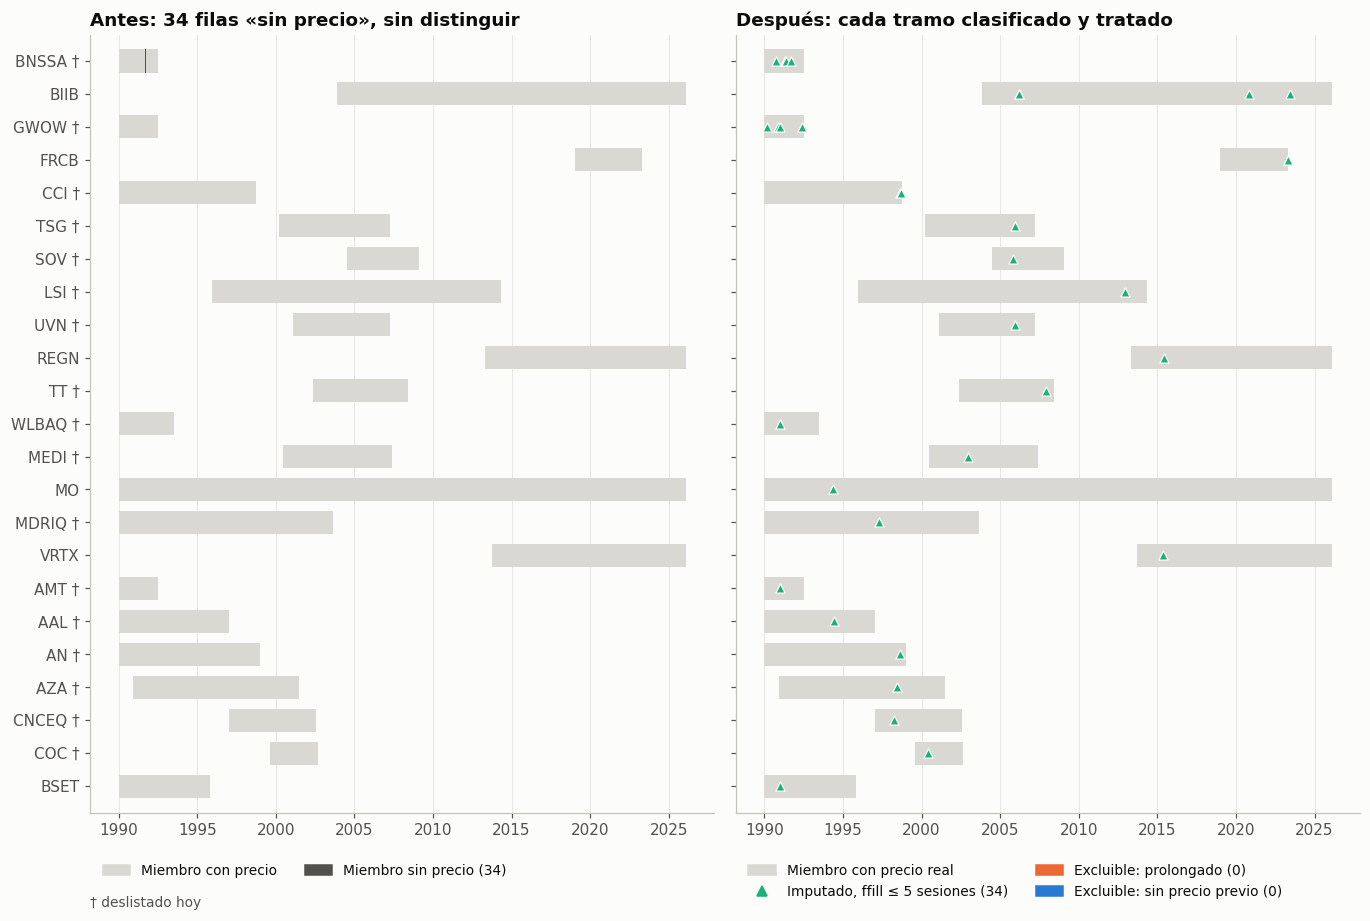

In [25]:
afectados = sin_precio.groupby('assetid').size().sort_values().index
etiquetas = [SIMBOLO[a].split('-')[0] + (' †' if metadata.loc[a, 'deslistado'] else '') for a in afectados]
datos_mapa = panel.loc[panel['assetid'].isin(afectados), ['date', 'assetid', 'has_price', 'tipo_hueco']]
grafico_mapa_huecos(datos_mapa, afectados, etiquetas, CAL, F)

**Lectura.** A diferencia del Nasdaq 100, aquí no hay ningún tramo naranja ni azul: todos los huecos son días sueltos (▲) que se rellenan con el último precio.

#### Efecto sobre los retornos: cálculo ingenuo frente a limpio

Mismo contraste que en el Nasdaq 100: la cartera equiponderada de los miembros con el retorno «desde el último precio disponible» (ingenuo) frente a `ret_tr_limpio`.

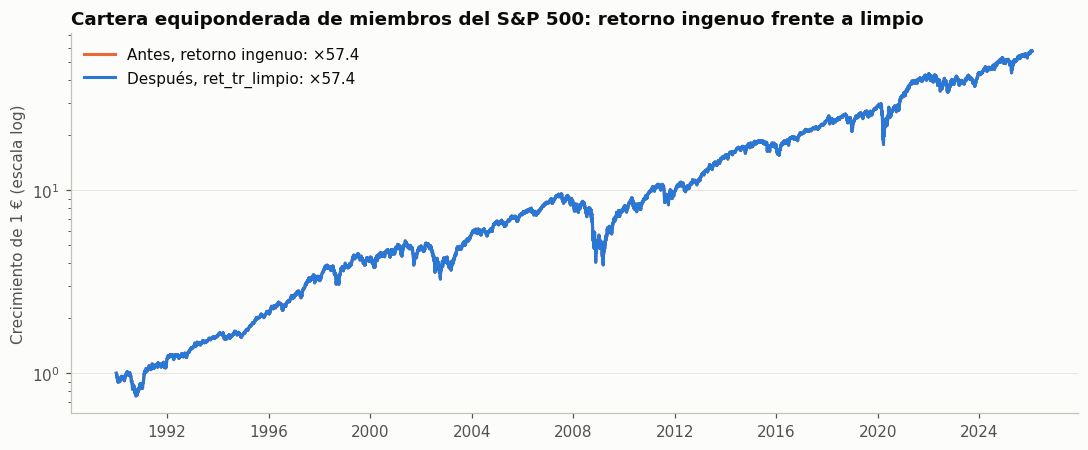

Diferencia final entre ambos cálculos: -0.0015% | máxima diferencia diaria: 1.11e-04


In [26]:
ingenuo = (panel['close_totalreturn'] / panel['close_tr_previo'] - 1).where(panel['has_price'])
ew_cmp = pd.DataFrame({'ingenuo': ingenuo.groupby(panel['date']).mean(),
                       'limpio': panel.groupby('date')['ret_tr_limpio'].mean()})
crec_cmp = (1 + ew_cmp.fillna(0)).cumprod()
grafico_crecimiento(crec_cmp, [('ingenuo', 'Antes, retorno ingenuo', COLOR['naranja']),
                               ('limpio', 'Después, ret_tr_limpio', COLOR['azul'])],
                    'Cartera equiponderada de miembros del S&P 500: retorno ingenuo frente a limpio',
                    'Crecimiento de 1 € (escala log)')
print(f"Diferencia final entre ambos cálculos: {crec_cmp['ingenuo'].iloc[-1] / crec_cmp['limpio'].iloc[-1] - 1:+.4%} | "
      f"máxima diferencia diaria: {(ew_cmp['ingenuo'] - ew_cmp['limpio']).abs().max():.2e}")

**Lectura.** Las dos curvas son **indistinguibles**. Sin huecos largos, el cálculo ingenuo y el limpio coinciden. Es el contraste con el Nasdaq 100, donde el cálculo ingenuo inflaba un 37 % el resultado: aquel problema venía de las particiones dañadas, no del método. El S&P 500 se puede usar casi tal cual. Aun así, las marcas de la limpieza (`precio_imputado`, `ret_anomalo`, `precio_congelado`…) mantienen el mismo criterio en los dos índices.

## 7. Exportación

El panel limpio contiene **solo las filas de pertenencia** (las del archivo con `in_sp500 = 1`, más los días sin precio de miembros) con todas las columnas originales y las columnas de limpieza. Las filas de no pertenencia del archivo no se exportan: siguen disponibles en `sp500_history.parquet`.

En los días sin precio de miembros:
- se rellena la metadata del valor (fija por valor) y `in_sp500 = 1`;
- OHLC y `unadjusted_close` toman el último cierre real (filas imputadas);
- `volume` queda vacío.

| Archivo en `datos_limpios/sp500/` | Contenido |
|---|---|
| `panel_pit_limpio.parquet` | Panel point-in-time limpio |
| `pertenencia_periodos.parquet` | Periodos reconstruidos (sección 2.2) |
| `log_decisiones.parquet` | Una fila por (fila del panel × decisión) |
| `cobertura_anual.parquet` | Tabla de la sección 6.1 |
| `informe_limpieza.json` | Parámetros, hashes, resultados |

In [27]:
COLUMNAS_NUEVAS = {
    'membership_period': 'Número de periodo de pertenencia del valor (reconstruido a partir de in_sp500)',
    'has_price': 'True si el archivo original tiene fila (precio real) ese día',
    'precio_imputado': 'True si el precio se ha rellenado con el último cierre real (ffill causal)',
    'sesiones_desde_ultimo_precio': 'Sesiones desde el último precio real estrictamente anterior',
    'fecha_ultimo_precio_real': 'Fecha del último precio real estrictamente anterior',
    'tipo_hueco': 'ninguno | imputado_ffill | prolongado_sin_imputar | sin_precio_previo',
    'precio_utilizable': 'has_price | precio_imputado',
    'excluible': 'True si la fila no tiene precio utilizable (no se borra: sigue siendo miembro)',
    'valor_descartado': 'True si el valor se descarta entero (opción A; False con la opción B elegida)',
    'ret_tr_limpio': 'Retorno diario sobre close (retorno total); NaN si no es fiable',
    'ret_none_limpio': 'Ídem sobre unadjusted_close (solo para validar splits)',
    'motivo_ret': 'normal | imputado_cero | acumulado_tras_hueco_corto | tras_hueco_largo | sin_precio | primer_precio',
    'ret_anomalo': f"|ret_tr_limpio| > {PARAMS['UMBRAL_RET_ANOMALO']}",
    'accion_corporativa_ajustada': 'El precio sin ajustar salta y el ajustado no (split u operación corporativa bien ajustada)',
    'posible_split_no_ajustado': 'Retorno anómalo con factor ~entero en ambas series: revisar',
    'sesiones_mismo_cierre': 'Sesiones seguidas, hasta ese día, con el mismo unadjusted_close',
    'precio_congelado': f"sesiones_mismo_cierre >= {PARAMS['RACHA_CONGELADO']} (racha contada solo hacia atrás)",
    'salida_por_fin_cotizacion': 'Última sesión de un periodo que termina porque termina la serie de precios',
    'ohlc_incoherente': 'low/high incoherentes con open/close en filas con precio real',
}

t0 = time.time()
esquema_original = pq.read_schema(ARCHIVO)
original = pd.read_parquet(ARCHIVO, filters=[('in_sp500', '==', 1)])
completo = panel[['date', 'assetid']].merge(original, on=['date', 'assetid'], how='left', validate='one_to_one')
del original
# Días sin precio de miembros: metadata del valor (fija) e in_sp500 = 1
sin_fila = completo['symbol'].isna()
for col in meta_cols:
    completo.loc[sin_fila, col] = completo.loc[sin_fila, 'assetid'].map(metadata[col])
completo.loc[sin_fila, 'in_sp500'] = 1
completo['in_sp500'] = completo['in_sp500'].astype('int32')

tabla = pa.Table.from_pandas(completo[esquema_original.names], schema=esquema_original, preserve_index=False)
del completo
tabla = sustituir_filas(tabla, imputados['fila'], imputados, ['open', 'high', 'low', 'close', 'unadjusted_close'])

nuevas = panel[list(COLUMNAS_NUEVAS)].copy()
nuevas['sesiones_desde_ultimo_precio'] = nuevas['sesiones_desde_ultimo_precio'].astype('Int32')
tabla = anadir_columnas(tabla, nuevas, COLUMNAS_NUEVAS)
del nuevas
ruta_panel = DIR_SALIDA / 'panel_pit_limpio.parquet'
escribir_parquet(tabla, ruta_panel, COLUMNAS_NUEVAS, PARAMS)
print(f'Escrito {ruta_panel.name}: {tabla.num_rows:,} filas × {tabla.num_columns} columnas | {time.time() - t0:.1f} s')
del tabla

periodos.to_parquet(DIR_SALIDA / 'pertenencia_periodos.parquet', index=False)
log = construir_log(panel, DECISIONES, SIMBOLO)
log.to_parquet(DIR_SALIDA / 'log_decisiones.parquet', index=False, compression='zstd')
cobertura_anual.reset_index().to_parquet(DIR_SALIDA / 'cobertura_anual.parquet', index=False)
print(f'log_decisiones: {len(log):,} filas')

Escrito panel_pit_limpio.parquet: 4,555,058 filas × 33 columnas | 17.2 s
log_decisiones: 3,090 filas


### 7.1 Verificación de la salida

In [28]:
salida = pd.read_parquet(ruta_panel, columns=['date', 'assetid', 'in_sp500', 'symbol', 'close', 'open', 'volume',
                                              'has_price', 'precio_imputado', 'excluible'])
assert len(salida) == len(panel) and not salida.duplicated(['date', 'assetid']).any()
assert (salida['in_sp500'] == 1).all() and salida['symbol'].notna().all()
assert salida.loc[salida['precio_imputado'], ['close', 'open']].notna().all().all()
assert salida.loc[salida['precio_imputado'], 'volume'].isna().all()
assert (salida['has_price'] | salida['precio_imputado'] == ~salida['excluible']).all()
for campo in esquema_original:
    assert pq.read_schema(ruta_panel).field(campo.name).type == campo.type, campo.name
del salida
verificar_hash(ARCHIVO, SHA256_REFERENCIA)
print('✔ salida verificada | ✔ archivo original sin cambios')

✔ salida verificada | ✔ archivo original sin cambios


In [29]:
informe = guardar_informe({
    'notebook': 'notebooks/02_limpieza_sp500.ipynb',
    'codigo_comun': 'src/limpieza_pit',
    'ejecutado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'entorno': {'python': platform.python_version(), 'pandas': pd.__version__, 'pyarrow': pa.__version__,
                'numpy': np.__version__},
    'parametros': PARAMS,
    'decisiones': {
        'pertenencia': 'periodos reconstruidos desde in_sp500; sesiones sin fila dentro de un periodo = hueco de precio',
        'pertenencia_ambigua': f'{int(ambiguo.sum())} tramos ({int(salto[ambiguo].sum())} sesiones) entre un 1 y un 0: fuera del panel',
        'precision': 'float32 convertido a float64 antes de calcular',
        'precio_para_retornos': 'close (retorno total); unadjusted_close solo para validar splits',
        'huecos_cortos': f"ffill causal hasta {PARAMS['FFILL_MAX_SESIONES']} sesiones, marcado en precio_imputado",
        'valores_con_muchos_huecos': 'opción B: no se descarta ningún valor completo',
        'sector_industria': 'clasificación actual (snapshot), no histórica: posible look-ahead si se usa como histórica',
        'huecos_nasdaq_recuperables': 'hallazgo documentado; no aplicado (pendiente de confirmar el origen del archivo)',
        'test_lookahead': f"filas idénticas con datos truncados en {PARAMS['CORTES_TEST_LOOKAHEAD']}; control negativo: interpolación",
    },
    'entrada': {'archivo': ARCHIVO.name, 'sha256': SHA256_REFERENCIA},
    'resultado': {
        'antes_despues': antes_despues.astype(int).to_dict(orient='index'),
        'decisiones': tabla_decisiones[['filas', 'valores']].astype(int).to_dict(orient='index'),
        'periodos': len(periodos),
        'huecos_nasdaq_con_precio_en_sp500': int(recuperables['close_totalreturn'].notna().sum()),
    },
    'columnas_nuevas': COLUMNAS_NUEVAS,
    'duracion_segundos': round(time.time() - T_INICIO, 1),
}, DIR_SALIDA)
for p in sorted(DIR_SALIDA.iterdir()):
    print(f'{p.name:32s} {p.stat().st_size / 1e6:8.2f} MB')
print(f"\nDuración total: {informe['duracion_segundos']} s")

cobertura_anual.parquet              0.01 MB
informe_limpieza.json                0.01 MB
log_decisiones.parquet               0.05 MB
panel_pit_limpio.parquet           164.92 MB
pertenencia_periodos.parquet         0.04 MB

Duración total: 71.2 s


## Resumen para los siguientes notebooks

- Leer **`datos_limpios/sp500/panel_pit_limpio.parquet`**: una fila por valor y día de pertenencia, incluidas las deslistadas.
- Mismas columnas de limpieza que el panel del Nasdaq 100. Para retornos, usar **`ret_tr_limpio`**.
- `sector`, `industry` y `subsector` son la clasificación **actual**: no usarlos como clasificación histórica sin advertirlo.
- Revisar antes de usar: `ret_anomalo`, `posible_split_no_ajustado` y `precio_congelado`.
- Pendiente con el profesor: origen de `sp500_history.parquet` y si se pueden usar sus precios para recuperar huecos del Nasdaq 100 (sección 5.6).